# How does firing change around a cue?

**Question:** Does a neuron fire more after a cue, and how soon does its
response appear? Compare individual cue presentations with the average
firing rate, then compare response timing across two neurons.

**You will need:** Spike times for each unit, cue times, and the periods when
spikes were recorded. All times must be in seconds on the same session clock.
We generate a short example with two neurons and a recording gap, so no data
files are needed.

**Estimated time**: 15-20 minutes

**Prerequisites**: [Spatial rate maps](02_spatial_rate_maps.ipynb).


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from neurospatial.events import (
    population_peri_event_histogram,
    time_to_nearest_event,
)
from neurospatial.simulation import generate_poisson_spikes

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(10, 6))

## 1. Prepare spike times and cue times

The example is a three-minute session with two simulated neurons, labeled
7 and 42. Both have a baseline firing rate of 2 Hz. We add an early response
to unit 7 and a later response to unit 42. The next cell generates the
example spike trains and cue times.

Spikes were not recorded from 80 to 100 s. We describe the recorded periods
with `spike_window`; a gap in recording must not count as time with no spikes.

In [2]:
event_rng = np.random.default_rng(42)
duration = 180.0
times = np.arange(0.0, duration + 0.001, 0.002)
regular_events = np.arange(10.0, 180.0, 15.0)
regular_events += event_rng.uniform(-0.3, 0.3, regular_events.size)
event_times = np.sort(np.r_[regular_events, [0.2, 79.8, 90.0, 100.2, 179.8]])
event_names = np.array([f"cue_{index:02d}" for index in range(len(event_times))])
spike_window = np.array([[0.0, 80.0], [100.0, duration]])
epochs = np.array([[5.0, 175.0]])  # separate analysis choice
unit_ids = np.array([7, 42])

spike_trains = []
for latency, amplitude, seed in [(0.15, 24.0, 142), (0.40, 14.0, 143)]:
    rate = np.full(times.size, 2.0)
    for event in event_times:
        rate += amplitude * np.exp(-0.5 * ((times - event - latency) / 0.08) ** 2)
    # Distinct seeds for event jitter and each unit's spike generation.
    spikes = generate_poisson_spikes(rate, times, seed=seed, refractory_period=0.0)
    recorded = np.zeros(spikes.size, dtype=bool)
    for start, stop in spike_window:
        recorded |= (spikes >= start) & (spikes < stop)
    spike_trains.append(spikes[recorded])

print(f"Cue presentations: {len(event_times)}; unit IDs: {unit_ids.tolist()}")
print(f"Recorded spikes per unit: {[len(train) for train in spike_trains]}")

Cue presentations: 17; unit IDs: [7, 42]
Recorded spikes per unit: [368, 378]


## 2. Choose a time window and calculate firing around each cue

We compare 500 ms before the cue with 1 s after it, using 25 ms bins.
`epochs` selects the part of the session to analyze. `spike_window` gives
the periods when electrophysiology was recording.

Keep a cue only if spikes were recorded throughout its analysis window.
A cue close to a recording gap or the edge of an analysis period is excluded.
Both the raster and the average below will use these same cue presentations.

In [3]:
window = (-0.5, 1.0)
bin_size = 0.025
population = population_peri_event_histogram(
    spike_trains,
    event_times,
    window=window,
    bin_size=bin_size,
    unit_ids=unit_ids,
    epochs=epochs,
    spike_window=spike_window,
)
result = population.sel(unit_id=7)
retained_events = event_times[result.event_indices]
retained_names = event_names[result.event_indices]
assert retained_events.size == result.n_events
np.testing.assert_array_equal(result.event_indices, population.event_indices)
assert result.n_events + result.n_events_dropped == event_times.size
print(f"Cues analyzed: {result.n_events}; excluded: {result.n_events_dropped}")
print(f"Cue labels used: {retained_names.tolist()}")

Cues analyzed: 9; excluded: 8
Cue labels used: ['cue_01', 'cue_02', 'cue_03', 'cue_04', 'cue_05', 'cue_11', 'cue_12', 'cue_13', 'cue_14']


## 3. Compare individual cue responses with the average

Each raster row is one cue presentation; each tick is a spike. The lower
panel is the peri-stimulus time histogram (PSTH), shown as a firing rate in Hz.
It averages the spike count across cues and divides by the bin width.

Pass the original cue array and the spike train for unit 7 to
`plot_peri_event_response`. The result tells the plot which cues to include.

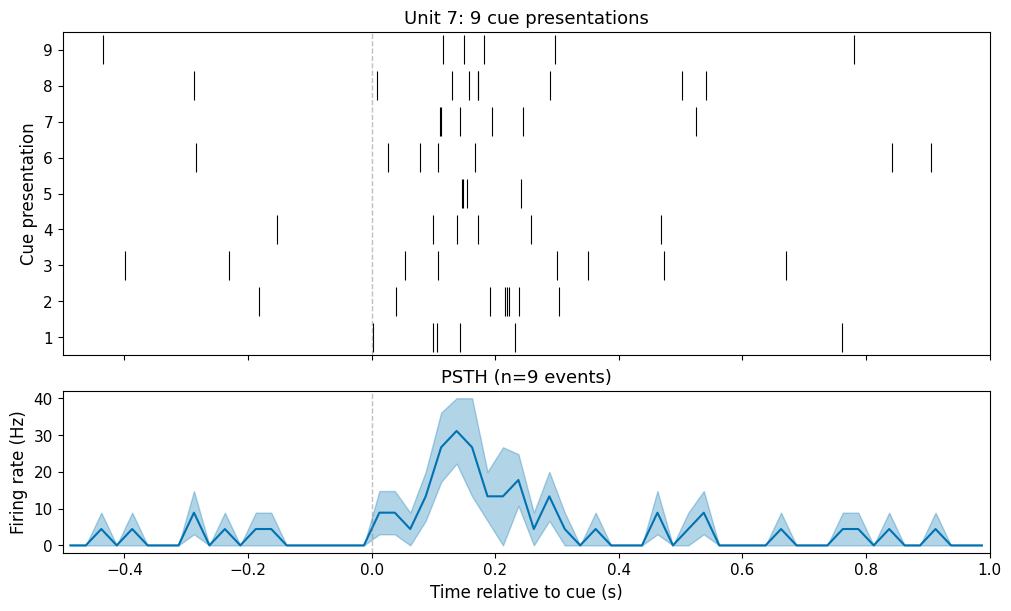

In [4]:
from neurospatial.events import plot_peri_event_response

raster_ax, rate_ax = plot_peri_event_response(spike_trains[0], event_times, result)
fig = raster_ax.figure
raster_ax.set_title(f"Unit {result.unit_id}: {result.n_events} cue presentations")
raster_ax.set_ylabel("Cue presentation")
raster_ax.set_yticks(
    np.arange(result.n_events), labels=np.arange(1, result.n_events + 1)
)
rate_ax.set_xlabel("Time relative to cue (s)")
plt.show()

Look for an increase after time zero, and compare it with firing before
the cue. The simulated response of unit 7 is centered at 150 ms. The raster
shows how spike timing varies across presentations even when the underlying
response is the same.

The shaded band is the SEM of the mean across cues, assuming independent
presentations. With one cue it is undefined (NaN). Repeated or overlapping
events can violate that independence assumption. In recorded hippocampal
activity, position, speed, or licking may also change around a cue; this plot
alone does not show that the cue caused a firing-rate change.

## 4. Compare response timing across neurons

Both rows below use the same cue presentations and the same time bins.
Compare unit 7's early response with unit 42's response, which was simulated
to peak at 400 ms. The colors show firing rate in Hz, without normalizing
each neuron's response, so baseline and response size also affect the colors.

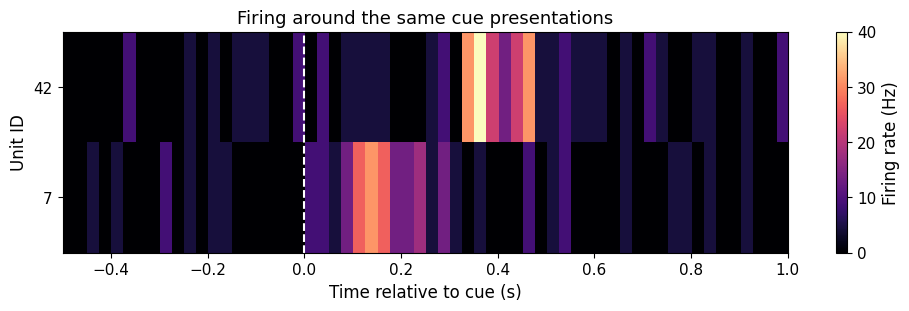

In [5]:
fig, ax = plt.subplots(figsize=(9, 3), constrained_layout=True)
image = ax.imshow(
    population.firing_rates,
    aspect="auto",
    origin="lower",
    extent=[window[0], window[1], -0.5, population.n_units - 0.5],
    cmap="magma",
)
ax.set_yticks(np.arange(population.n_units), labels=population.unit_ids)
ax.axvline(0, color="white", linestyle="--")
ax.set(
    xlabel="Time relative to cue (s)",
    ylabel="Unit ID",
    title="Firing around the same cue presentations",
)
fig.colorbar(image, ax=ax, label="Firing rate (Hz)")
plt.show()

## 5. Check which cue presentations were excluded

The plot below places included and excluded cues on the session clock.
A cue can occur during recording and still be excluded if its full analysis
window crosses the gap. `result.event_indices` gives the original cue-array
positions, so we can also look up labels such as `retained_names` above.

Spike-counting intervals include their start and exclude their stop:
`[start, stop)`. If the analysis window is not divisible by `bin_size`, the
final partial bin is left out of both the raster and PSTH. The full requested
window must still lie within a recorded period.

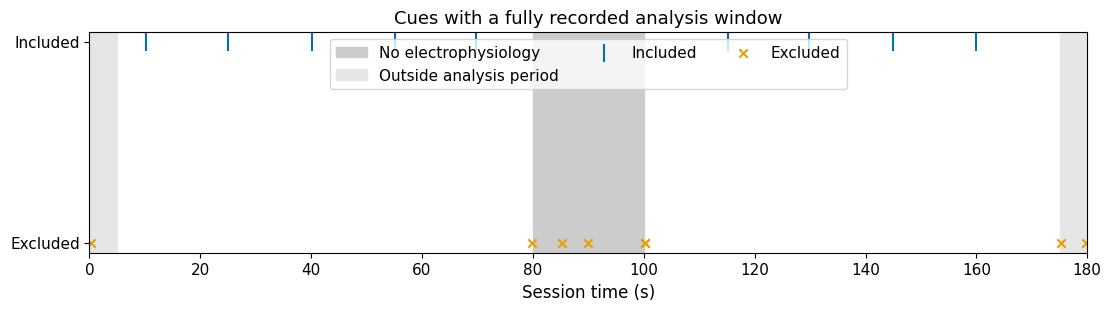

In [6]:
retained = np.zeros(event_times.size, dtype=bool)
retained[result.event_indices] = True
fig, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
ax.axvspan(80, 100, color="0.8", label="No electrophysiology")
ax.axvspan(0, 5, color="0.9", label="Outside analysis period")
ax.axvspan(175, duration, color="0.9")
ax.scatter(
    event_times[retained], np.ones(retained.sum()), marker="|", s=180, label="Included"
)
ax.scatter(
    event_times[~retained], np.zeros((~retained).sum()), marker="x", label="Excluded"
)
ax.set(xlim=(0, duration), yticks=[0, 1], yticklabels=["Excluded", "Included"])
ax.set_xlabel("Session time (s)")
ax.set_title("Cues with a fully recorded analysis window")
ax.legend(loc="upper center", ncol=3)
plt.show()

## 6. Optional: describe time before and after the nearest cue

A model of firing may include an animal's position, speed, and time relative
to a cue. Here, negative values mean a cue is approaching and positive values
mean it has passed. This variable uses the nearest cue, including future cues,
and jumps halfway between them. It is suitable for describing a completed
session. For prediction using only past information, use time since the last
cue. We construct the variable here without fitting a firing-rate model.

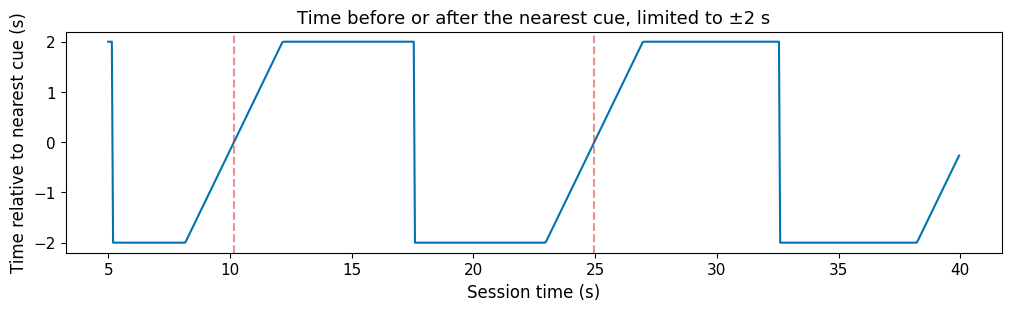

In [7]:
sample_times = np.arange(5.0, 40.0, 0.05)
nearest = time_to_nearest_event(sample_times, event_times, signed=True, max_time=2.0)
fig, ax = plt.subplots(figsize=(10, 3), constrained_layout=True)
ax.plot(sample_times, nearest)
for event in event_times[(event_times >= 5) & (event_times < 40)]:
    ax.axvline(event, color="tab:red", linestyle="--", alpha=0.5)
ax.set(
    xlabel="Session time (s)",
    ylabel="Time relative to nearest cue (s)",
    ylim=(-2.2, 2.2),
)
ax.set_title("Time before or after the nearest cue, limited to ±2 s")
plt.show()

## Use your own recording

Replace `spike_trains` with one spike-time array per unit and `event_times`
with your cue, reward-delivery, or other measured event times. Keep `unit_ids`
in the same order as the spike trains. Use seconds and synchronize all streams
before alignment. Set `spike_window` from acquisition records and choose
`epochs` for the behavior or task period you want to compare.

Choose the window and bin width for the response timing you expect. Check
individual presentations as well as the mean, and report how many events
were excluded. For an experiment with several conditions, analyze each
condition explicitly rather than pooling different types of event.

[Analyze an NWB recording](09_nwb_io.ipynb) shows how to load spike trains and
recorded periods. [Inspect spatial maps alongside behavior](08_visualization.ipynb)
shows how to view spatial signals together with tracking and event markers.